# SV context composition per ecotype, and why TE and promoter compete

The cascade figure in `sv_context_cascade.ipynb` shows the context split of the SV events *pooled over all
founders*. This notebook opens that bar up: one stacked bar **per ecotype**, ordered by sequencing
technology and tagged with origin climate, followed by the between-context correlations across the 231
founders.

**The motivating observation.** In the pooled burden models, dropping the `sv_TE` term moves the promoter ×
temperature interaction from Bonferroni 0.050 to 0.00029 — a ~170× change — while leaving the Model 1
overall effects almost untouched (`sv_burden_pooled_nofilter.ipynb` vs `sv_burden_pooled_nofilter_noTE.ipynb`).
That is the signature of two predictors carrying overlapping information: whichever is in the model absorbs
variance the other would otherwise explain. Whether that is really what is happening is a statement about
the **founder-level burdens**, not about the fit, so it can be checked directly here.

**Unit.** Everything is **events** — truvari-collapsed SV events from `founder_burden_event.csv`, the same
table the burden models are fitted on. No allele-level counts appear anywhere in this notebook.

**Two quantities, kept apart throughout.**

- **Composition** — of the SV events a founder *carries*, what fraction falls in each context. This is the
  per-ecotype version of the cascade bar, and it sums to 100 % by construction.
- **Burden rate** — carried / called within a context, the quantity the models actually use. Rates are not
  constrained to sum to anything, and they are the right unit for asking whether two contexts covary.

A founder can look unremarkable in composition and still be an outlier in rate, because the number of
events *called* in a founder varies; composition divides that out, rates do not.

In [1]:

import os, glob
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi":120,"font.size":8,"axes.linewidth":0.6,"savefig.bbox":"tight","legend.frameon":False})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive")); os.makedirs(f"{G}/plots",exist_ok=True)
# colours: insertions forest green, deletions orange, SNPs grey; dark -> light = coding -> promoter -> intergenic
# (no blue or red: those are the garden-temperature scale)
PAL={"snp_CDS":"0.25","snp_promoter":"0.45","snp_intergenic":"0.65",
     "ins_CDS":"#2F4A1F","ins_promoter":"#4E6B3A","ins_intergenic":"#9DB58C",
     "del_CDS":"#B04A00","del_promoter":"#F07A2E","del_intergenic":"#F8BE91"}; PC=lambda t: PAL[t.split(":")[0]]         # colour of a term (interactions take their term's colour)
def style(a,axis="x"):
    a.set_axisbelow(True); a.grid(color="0.9",lw=0.6,axis=axis)
    for s_ in a.spines.values(): s_.set_visible(False)
def panel(a,letter,x=-0.08,y=1.04): a.annotate(letter,xy=(x,y),xycoords="axes fraction",fontsize=11,fontweight="bold",ha="right")
M="\u2212"
def pct(v,d=3): return f"{v:+.{d}g}%".replace("-",M)
NBPLOTS=os.path.join(os.getcwd(),"plots"); os.makedirs(NBPLOTS,exist_ok=True)          # notebooks/plots/, for the figures kept with the notebook
def save(fig,name,nb=False):
    for d in ([f"{G}/plots"]+([NBPLOTS] if nb else [])):
        fig.savefig(f"{d}/{name}.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{d}/{name}.pdf",bbox_inches="tight")


In [2]:

import numpy as np, pandas as pd
from scipy import stats as sps0
R1=G                                                       # results/sv_adaptive, from the shared setup cell
CTX6=["CDS","UTR","intron","TE","promoter","intergenic"]
MODCTX=["CDS","TE","promoter","intergenic"]                # the contexts that carry a burden term
# context palette lifted from _build_context_cascade_nb.py so the per-ecotype bars match the cascade bar
CC={"CDS":"#2F4A1F","UTR":"#4E6B3A","intron":"#7E9B6B","TE":"#C46A10","promoter":"#5B7A99","intergenic":"#B9B9B9"}

# founder_burden_event.csv already carries the founder metadata (bio1 = origin climate, group = cold/
# temperate/warm tertile, is_cactus = assembly route); verified identical to sv_origin_partition_founders.csv
# on all 231 founders, so one read is enough and the metadata cannot drift from the burden rows.
D=pd.read_csv(f"{R1}/founder_burden_event.csv")            # EVENTS (truvari-collapsed), not alleles
D["founder"]=D.founder.astype(str)
assert len(D)==231 and D.founder.is_unique, len(D)
_F=pd.read_csv(f"{R1}/sv_origin_partition_founders.csv"); _F["founder"]=_F.founder.astype(str)
_chk=_F.merge(D[["founder","bio1","group","is_cactus"]],on="founder",suffixes=("_p",""))
assert np.allclose(_chk.bio1_p,_chk.bio1) and (_chk.is_cactus_p==_chk.is_cactus).all() \
       and (_chk.group_p==_chk["group"]).all(), "founder metadata disagrees between the two tables"

# carried / called EVENTS per context, insertions + deletions pooled, no origin filter (the `all` arm)
car=pd.DataFrame({c: D[f"ins_all_{c}_all"]+D[f"del_all_{c}_all"] for c in CTX6})
cal=pd.DataFrame({c: D[f"called_ins_all_{c}_all"]+D[f"called_del_all_{c}_all"] for c in CTX6})
comp=car.div(car.sum(axis=1),axis=0)*100                   # composition, % of the founder's carried events
rate=car/cal                                               # burden rate, the model's quantity
for df in (car,cal,comp,rate): df.index=D.founder.values

AP=pd.read_csv(f"{R1}/sv_event_catalog.csv").query("passes")   # per-context denominators for call rate
TECH=np.where(D.is_cactus.to_numpy(),"cactus","short-read")
BIO1=D.bio1.to_numpy(); GRP=D.group.to_numpy()
print(f"{len(D)} founders | technology: "+", ".join(f"{k} {int(v)}" for k,v in pd.Series(TECH).value_counts().items()))
print("climate origin groups: "+", ".join(f"{k} {int(v)}" for k,v in pd.Series(GRP).value_counts().items())
      +f"   (origin bio1 {BIO1.min():.1f} to {BIO1.max():.1f} °C)")
print(f"\ncarried SV events per founder: median {int(car.sum(axis=1).median()):,} "
      f"(range {int(car.sum(axis=1).min()):,}–{int(car.sum(axis=1).max()):,})")
print("\npooled composition over all founders (%), for reference against the cascade bar:")
print((car.sum()/car.sum().sum()*100).round(1).to_string())
print("\nper-founder composition, spread across ecotypes (%):")
print(comp.describe().loc[["mean","std","min","max"]].round(2).to_string())


231 founders | technology: short-read 151, cactus 80
climate origin groups: temperate 77, warm 77, cold 77   (origin bio1 -4.3 to 22.7 °C)

carried SV events per founder: median 1,972 (range 652–3,385)

pooled composition over all founders (%), for reference against the cascade bar:
CDS            7.5
UTR            6.9
intron        16.8
TE            21.5
promoter      23.3
intergenic    24.1

per-founder composition, spread across ecotypes (%):
       CDS   UTR  intron     TE  promoter  intergenic
mean  7.53  6.90   16.83  21.65     23.08       24.01
std   0.53  0.48    0.88   1.29      1.32        1.11
min   6.07  5.74   14.72  17.51     19.24       19.29
max   9.13  8.90   19.55  27.41     26.89       27.37


## 1 · One bar per ecotype

Two panels over the same 231 founders, in the same order.

**(a) Counts** — how many SV **events** each ecotype carries, stacked by context. This is the quantity that
varies most between founders and the one the composition view hides.

**(b) Composition** — the same bars rescaled to 100 %, i.e. the per-ecotype version of the cascade figure.

Founders are blocked by **sequencing technology** (short-read first, then cactus assembly) and, within a
block, sorted by total carried events. The strip underneath tags **origin climate** (bio1 at the
accession's home location) on the usual coolwarm temperature scale — it is deliberately not sorted on, so
any climate structure has to show up as visible clustering rather than being imposed by the ordering.

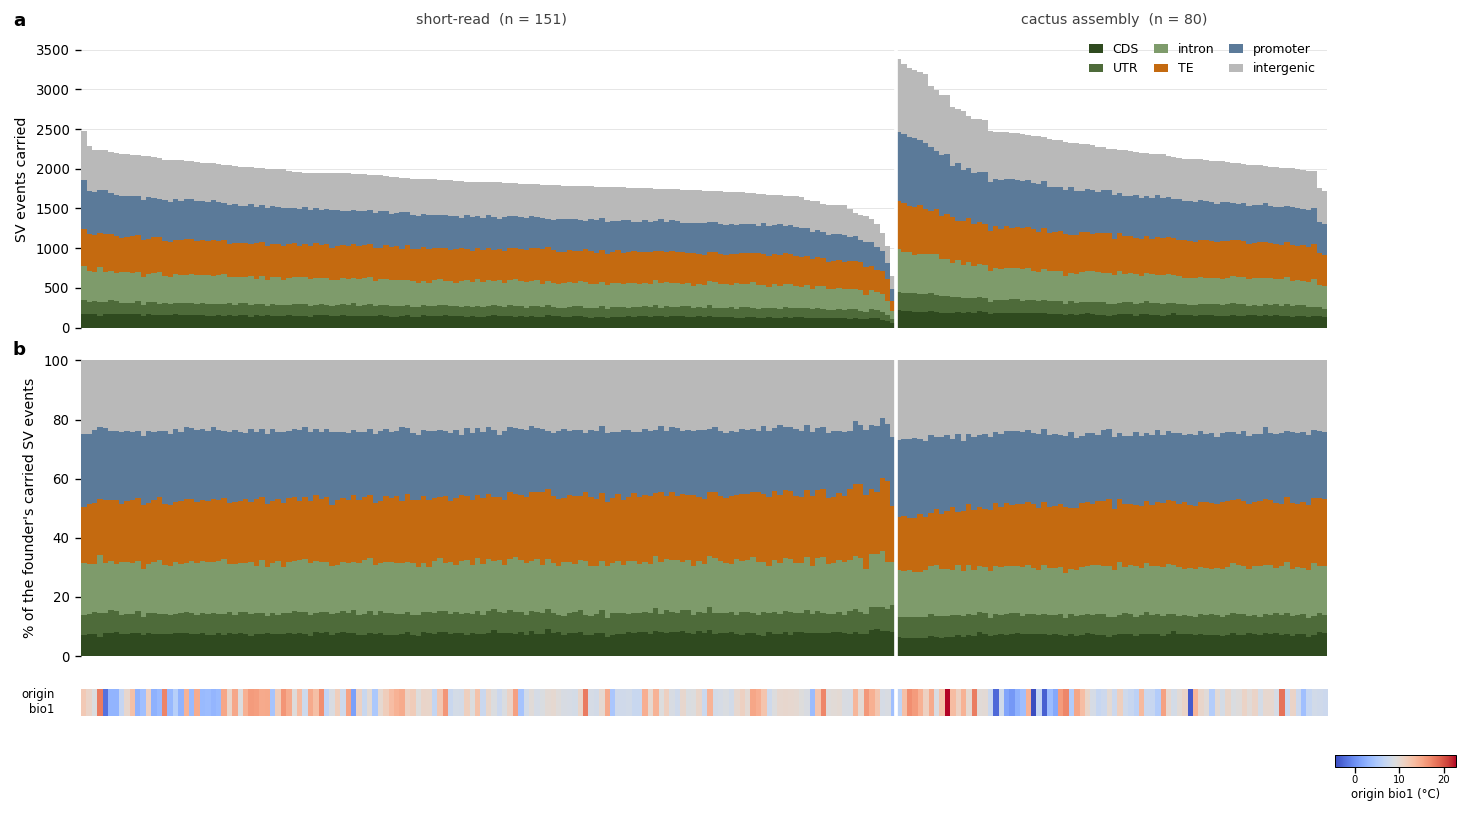

carried SV events per founder, by technology:
  short-read  n=151   median  1,827   range 652-2,470
  cactus      n= 80   median  2,249   range 1,722-3,385

Mann-Whitney short-read vs cactus, total events: p = 1.44e-25

mean events per founder by context and technology:
            short-read  cactus  difference
CDS              141.5   168.0        26.5
UTR              128.5   158.6        30.1
intron           316.0   379.9        63.9
TE               402.3   491.8        89.5
promoter         417.2   568.2       151.0
intergenic       434.0   587.8       153.8

composition by technology (mean %, events):
            short-read  cactus  difference
CDS               7.71    7.19       -0.52
UTR               7.00    6.71       -0.29
intron           17.18   16.17       -1.01
TE               21.96   21.07       -0.89
promoter         22.59   24.00        1.41
intergenic       23.56   24.87        1.31

composition by climate-origin group (mean %, events):
             cold  temperat

In [3]:

from matplotlib.patches import Patch
IS_C=D.is_cactus.to_numpy().astype(int)                    # 0 = short-read, 1 = cactus -> short-read block first
ordr=np.lexsort((-car.sum(axis=1).to_numpy(), IS_C))       # technology block, then total events within block
assert (IS_C[ordr][:int((IS_C==0).sum())]==0).all(), "technology blocks not contiguous"
nsr=int((TECH=="short-read").sum()); x=np.arange(len(ordr)); TOT=car.sum(axis=1)
fig=plt.figure(figsize=(13.4,7.4))
gsb=fig.add_gridspec(3,1,height_ratios=[10,10,0.9],hspace=0.16)
for row,(M,ylab) in enumerate(((car,"SV events carried"),(comp,"% of the founder's carried SV events"))):
    a=fig.add_subplot(gsb[row]); style(a,axis="y"); bot=np.zeros(len(ordr))
    for c in CTX6:
        v=M[c].to_numpy()[ordr]; a.bar(x,v,bottom=bot,width=1.0,color=CC[c],lw=0); bot+=v
    a.set_xlim(-0.5,len(ordr)-0.5); a.set_xticks([]); a.set_ylabel(ylab,fontsize=8.5)
    a.axvline(nsr-0.5,color="white",lw=2.2); panel(a,"ab"[row],x=-0.045,y=1.02)
    if row==0:
        a.set_ylim(0,TOT.max()*1.10)
        for lab,x0,x1 in (("short-read",0,nsr),("cactus assembly",nsr,len(ordr))):
            a.annotate(f"{lab}  (n = {x1-x0})",xy=((x0+x1)/2,TOT.max()*1.12),ha="center",
                       va="bottom",fontsize=8.5,color="0.25",annotation_clip=False)
        a.legend(handles=[Patch(facecolor=CC[c],label=c) for c in CTX6],loc="upper right",
                 ncol=3,fontsize=7.5,columnspacing=1.2,handlelength=1.1)
    else:
        a.set_ylim(0,100)
s=fig.add_subplot(gsb[2])                                   # origin-climate tag strip
NORMc=mpl.colors.Normalize(BIO1.min(),BIO1.max()); CMc=plt.get_cmap("coolwarm")
s.imshow(BIO1[ordr][None,:],aspect="auto",cmap=CMc,norm=NORMc,interpolation="nearest")
s.set_yticks([]); s.set_xticks([]); s.set_xlim(-0.5,len(ordr)-0.5)
s.axvline(nsr-0.5,color="white",lw=2.2)
s.set_ylabel("origin\nbio1",fontsize=7,rotation=0,ha="right",va="center",labelpad=16)
for sp in s.spines.values(): sp.set_visible(False)
cax=fig.add_axes([0.905,0.052,0.075,0.014])                 # own axes: ax=[s] steals the strip's width
cb=fig.colorbar(mpl.cm.ScalarMappable(norm=NORMc,cmap=CMc),cax=cax,orientation="horizontal")
cb.set_label("origin bio1 (°C)",fontsize=7,labelpad=2); cb.ax.tick_params(labelsize=6,pad=1)
save(fig,"founder_context_composition",nb=True); plt.show()

print("carried SV events per founder, by technology:")
for t in ("short-read","cactus"):
    v=TOT[TECH==t]
    print(f"  {t:<11} n={len(v):>3}   median {int(v.median()):>6,}   range {int(v.min()):,}-{int(v.max()):,}")
print("\nMann-Whitney short-read vs cactus, total events: p = "
      f"{sps0.mannwhitneyu(TOT[TECH=='short-read'],TOT[TECH=='cactus']).pvalue:.3g}")
print("\nmean events per founder by context and technology:")
Tn=pd.DataFrame({t: car[TECH==t].mean() for t in ("short-read","cactus")}).round(1)
Tn["difference"]=(Tn["cactus"]-Tn["short-read"]).round(1); print(Tn.to_string())
print("\ncomposition by technology (mean %, events):")
T=pd.DataFrame({t: comp[TECH==t].mean() for t in ("short-read","cactus")}).round(2)
T["difference"]=(T["cactus"]-T["short-read"]).round(2); print(T.to_string())
print("\ncomposition by climate-origin group (mean %, events):")
print(pd.DataFrame({g: comp[GRP==g].mean() for g in ("cold","temperate","warm")}).round(2).to_string())


## 1b · The same picture as a rate, correcting for call rate

Panel (a) above counts the events a founder *carries*, which confounds two things: how many SVs the founder
really has, and how many SVs were **callable** in it. Founders differ a lot in the latter, and the cactus
and short-read panels differ systematically, so a count gradient can be a calling gradient.

This repeats the figure on the **burden rate** — carried / called *within each context*, the quantity the
burden models are actually fitted on. Denominators are per context, so the stacked total in (a) is a sum of
four rates rather than a count; it is a profile, not a total, and only the per-context bands should be read
off it.

**(a)** per-context burden rate, stacked · **(b)** the same rescaled to 100 % — composition after call-rate
correction · **(c)** the call rate being corrected for: events called in that founder as a fraction of all
events in that context. Ordering is by total rate within technology block, so it is *not* the same founder
order as §1 — that is deliberate, since the point is whether the gradient survives the correction.

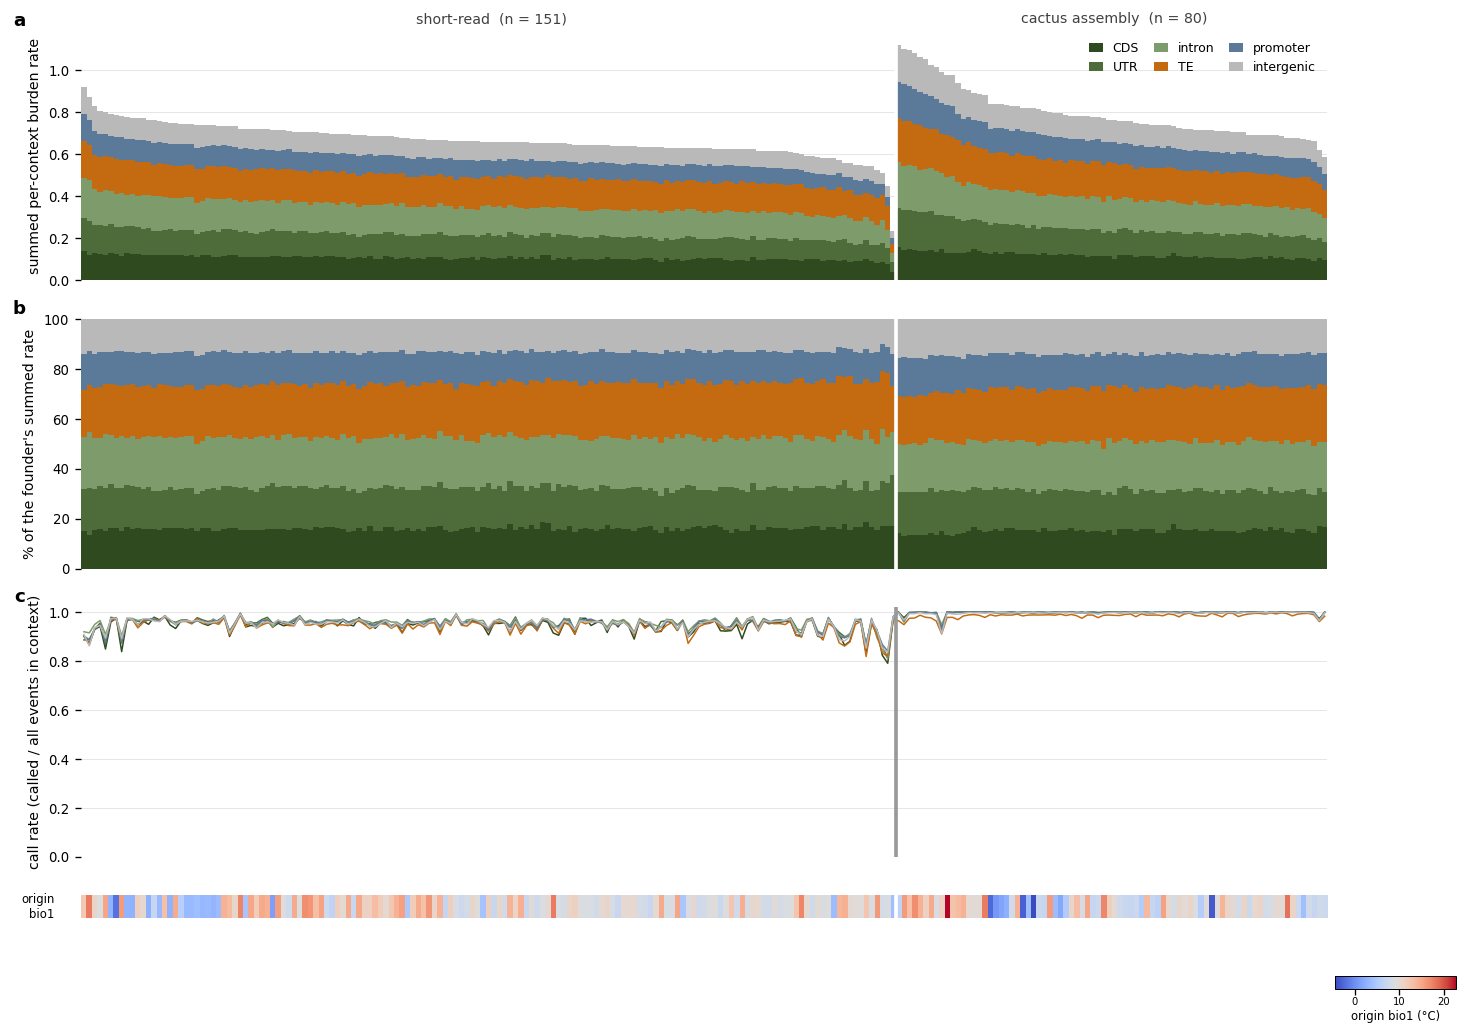

call rate per founder (called / all events in that context), by technology:
            short-read  cactus
CDS              0.942   0.996
UTR              0.951   0.997
intron           0.955   0.997
TE               0.941   0.984
promoter         0.950   0.997
intergenic       0.949   0.994

DOES THE TECHNOLOGY DIFFERENCE SURVIVE THE CORRECTION?
  counts  short-read median 1,827  cactus 2,249   MWU p = 1.44e-25
  rates   short-read median 0.6606  cactus 0.7635   MWU p = 3.9e-18

per-context burden rate by technology (mean):
            short-read  cactus  difference
CDS             0.1066  0.1199      0.0133
UTR             0.1095  0.1289      0.0194
intron          0.1349  0.1555      0.0206
TE              0.1440  0.1684      0.0244
promoter        0.0846  0.1100      0.0254
intergenic      0.0883  0.1142      0.0259

rate-based composition by technology (mean %):
            short-read  cactus  difference
CDS              15.99   15.13       -0.86
UTR              16.39   16.08    

In [4]:

NCTX=AP.context.value_counts().reindex(CTX6)               # events per context in the passing pool
crate=cal.div(NCTX,axis=1)                                 # call rate: called / all events in that context
RTOT=rate[CTX6].sum(axis=1)                                # summed per-context rates (a profile, not a total)
ordr2=np.lexsort((-RTOT.to_numpy(), IS_C))                 # technology block, then total RATE within block
fig=plt.figure(figsize=(13.4,9.6))
gsr=fig.add_gridspec(4,1,height_ratios=[10,10,10,0.9],hspace=0.20)
for row,(M,ylab) in enumerate(((rate[CTX6],"summed per-context burden rate"),
                               (rate[CTX6].div(RTOT,axis=0)*100,"% of the founder's summed rate"),
                               (crate,"call rate (called / all events in context)"))):
    a=fig.add_subplot(gsr[row]); style(a,axis="y"); bot=np.zeros(len(ordr2))
    if row<2:
        for c in CTX6:
            v=M[c].to_numpy()[ordr2]; a.bar(x,v,bottom=bot,width=1.0,color=CC[c],lw=0); bot+=v
        a.set_ylim(0,(RTOT.max()*1.06) if row==0 else 100)
    else:                                                   # call rate is per context, not additive: draw as lines
        for c in CTX6:
            a.plot(x,M[c].to_numpy()[ordr2],color=CC[c],lw=0.9)
        a.set_ylim(0,1.02); a.set_ylabel(ylab,fontsize=8.5)
    a.set_xlim(-0.5,len(ordr2)-0.5); a.set_xticks([])
    if row<2: a.set_ylabel(ylab,fontsize=8.5)
    a.axvline(nsr-0.5,color="white" if row<2 else "0.6",lw=2.2); panel(a,"abc"[row],x=-0.045,y=1.02)
    if row==0:
        for lab,x0,x1 in (("short-read",0,nsr),("cactus assembly",nsr,len(ordr2))):
            a.annotate(f"{lab}  (n = {x1-x0})",xy=((x0+x1)/2,RTOT.max()*1.08),ha="center",va="bottom",
                       fontsize=8.5,color="0.25",annotation_clip=False)
        a.legend(handles=[Patch(facecolor=CC[c],label=c) for c in CTX6],loc="upper right",
                 ncol=3,fontsize=7.5,columnspacing=1.2,handlelength=1.1)
s=fig.add_subplot(gsr[3])
s.imshow(BIO1[ordr2][None,:],aspect="auto",cmap=CMc,norm=NORMc,interpolation="nearest")
s.set_yticks([]); s.set_xticks([]); s.set_xlim(-0.5,len(ordr2)-0.5)
s.axvline(nsr-0.5,color="white",lw=2.2)
s.set_ylabel("origin\nbio1",fontsize=7,rotation=0,ha="right",va="center",labelpad=16)
for sp in s.spines.values(): sp.set_visible(False)
cax=fig.add_axes([0.905,0.048,0.075,0.011])
cb=fig.colorbar(mpl.cm.ScalarMappable(norm=NORMc,cmap=CMc),cax=cax,orientation="horizontal")
cb.set_label("origin bio1 (°C)",fontsize=7,labelpad=2); cb.ax.tick_params(labelsize=6,pad=1)
save(fig,"founder_context_rate",nb=True); plt.show()

print("call rate per founder (called / all events in that context), by technology:")
print(pd.DataFrame({t: crate[TECH==t].mean() for t in ("short-read","cactus")}).round(3).to_string())
print("\nDOES THE TECHNOLOGY DIFFERENCE SURVIVE THE CORRECTION?")
print(f"  counts  short-read median {int(TOT[TECH=='short-read'].median()):,}  "
      f"cactus {int(TOT[TECH=='cactus'].median()):,}   "
      f"MWU p = {sps0.mannwhitneyu(TOT[TECH=='short-read'],TOT[TECH=='cactus']).pvalue:.3g}")
print(f"  rates   short-read median {RTOT[TECH=='short-read'].median():.4f}  "
      f"cactus {RTOT[TECH=='cactus'].median():.4f}   "
      f"MWU p = {sps0.mannwhitneyu(RTOT[TECH=='short-read'],RTOT[TECH=='cactus']).pvalue:.3g}")
print("\nper-context burden rate by technology (mean):")
Tr=pd.DataFrame({t: rate[CTX6][TECH==t].mean() for t in ("short-read","cactus")}).round(4)
Tr["difference"]=(Tr["cactus"]-Tr["short-read"]).round(4); print(Tr.to_string())
print("\nrate-based composition by technology (mean %):")
rcomp=rate[CTX6].div(RTOT,axis=0)*100
Tc=pd.DataFrame({t: rcomp[TECH==t].mean() for t in ("short-read","cactus")}).round(2)
Tc["difference"]=(Tc["cactus"]-Tc["short-read"]).round(2); print(Tc.to_string())
print("\ncount-based vs rate-based composition (mean %, all founders):")
print(pd.DataFrame({"by counts":comp.mean(),"by rates":rcomp.mean(),
                    "shift":(rcomp.mean()-comp.mean())}).round(2).to_string())
print("\nrate-based composition by climate-origin group (mean %):")
print(pd.DataFrame({g: rcomp[GRP==g].mean() for g in ("cold","temperate","warm")}).round(2).to_string())


## 1c · The two values per ecotype, one above the other

The comparison that matters for the bias question: **(a)** the raw count of SV events each ecotype carries,
and directly beneath it **(b)** the same ecotype's burden *rate*, carried / called within each context.

Both panels use the **same founder order** — technology block, then total carried events — so each column is
the same ecotype in both. If dividing by call rate mattered, panel (b) would reorder or reshape relative to
panel (a). The printed correlations say how much it actually changes.

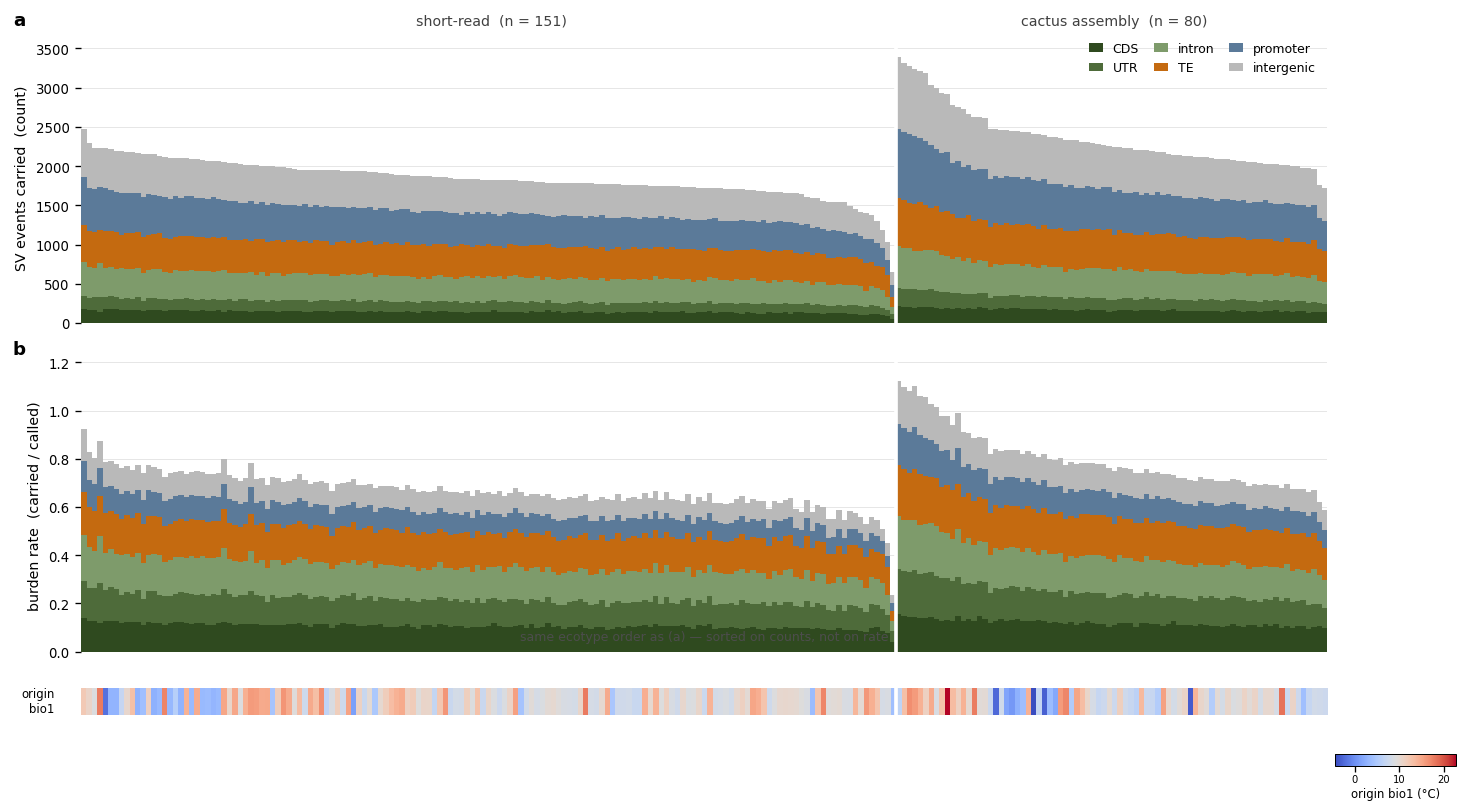

how much does dividing by call rate change the ecotype ranking?

   context  carried CV %  called CV %  Pearson r(count, rate)  Spearman
       CDS        14.593        3.841                   0.972     0.961
       UTR        19.493        3.240                   0.987     0.982
    intron        16.704        2.999                   0.987     0.984
        TE        14.162        3.395                   0.979     0.973
  promoter        24.074        3.177                   0.993     0.991
intergenic        22.624        3.228                   0.993     0.989
     TOTAL        18.812        3.221                   0.989     0.985

The denominator varies ~6x less than the numerator and count/rate correlate at ~0.99,
so the call-rate correction rescales the bars but does not reorder the ecotypes:
call rate is a small nuisance on top of the signal, not the thing driving founder differences.


In [5]:

fig=plt.figure(figsize=(13.4,7.4))
gsp=fig.add_gridspec(3,1,height_ratios=[10,10,0.9],hspace=0.18)
RT=rate[CTX6].sum(axis=1)
for row,(M,ylab,ymax) in enumerate(((car,"SV events carried  (count)",TOT.max()*1.10),
                                    (rate[CTX6],"burden rate  (carried / called)",RT.max()*1.08))):
    a=fig.add_subplot(gsp[row]); style(a,axis="y"); bot=np.zeros(len(ordr))
    for c in CTX6:
        v=M[c].to_numpy()[ordr]; a.bar(x,v,bottom=bot,width=1.0,color=CC[c],lw=0); bot+=v
    a.set_xlim(-0.5,len(ordr)-0.5); a.set_xticks([]); a.set_ylim(0,ymax)
    a.set_ylabel(ylab,fontsize=8.5); a.axvline(nsr-0.5,color="white",lw=2.2)
    panel(a,"ab"[row],x=-0.045,y=1.02)
    if row==0:
        for lab,x0,x1 in (("short-read",0,nsr),("cactus assembly",nsr,len(ordr))):
            a.annotate(f"{lab}  (n = {x1-x0})",xy=((x0+x1)/2,ymax*1.01),ha="center",va="bottom",
                       fontsize=8.5,color="0.25",annotation_clip=False)
        a.legend(handles=[Patch(facecolor=CC[c],label=c) for c in CTX6],loc="upper right",
                 ncol=3,fontsize=7.5,columnspacing=1.2,handlelength=1.1)
    else:
        a.annotate("same ecotype order as (a) — sorted on counts, not on rate",
                   xy=(0.5,0.04),xycoords="axes fraction",ha="center",fontsize=7.5,color="0.3")
s=fig.add_subplot(gsp[2])
s.imshow(BIO1[ordr][None,:],aspect="auto",cmap=CMc,norm=NORMc,interpolation="nearest")
s.set_yticks([]); s.set_xticks([]); s.set_xlim(-0.5,len(ordr)-0.5)
s.axvline(nsr-0.5,color="white",lw=2.2)
s.set_ylabel("origin\nbio1",fontsize=7,rotation=0,ha="right",va="center",labelpad=16)
for sp in s.spines.values(): sp.set_visible(False)
cax=fig.add_axes([0.905,0.052,0.075,0.014])
cb=fig.colorbar(mpl.cm.ScalarMappable(norm=NORMc,cmap=CMc),cax=cax,orientation="horizontal")
cb.set_label("origin bio1 (°C)",fontsize=7,labelpad=2); cb.ax.tick_params(labelsize=6,pad=1)
save(fig,"founder_count_vs_rate",nb=True); plt.show()

print("how much does dividing by call rate change the ecotype ranking?\n")
rr=[]
for c in CTX6:
    rr.append({"context":c,
               "carried CV %":100*car[c].std()/car[c].mean(),
               "called CV %":100*cal[c].std()/cal[c].mean(),
               "Pearson r(count, rate)":np.corrcoef(car[c],rate[c])[0,1],
               "Spearman":sps0.spearmanr(car[c],rate[c]).correlation})
rr.append({"context":"TOTAL","carried CV %":100*TOT.std()/TOT.mean(),
           "called CV %":100*cal.sum(1).std()/cal.sum(1).mean(),
           "Pearson r(count, rate)":np.corrcoef(TOT,TOT/cal.sum(1))[0,1],
           "Spearman":sps0.spearmanr(TOT,TOT/cal.sum(1)).correlation})
print(pd.DataFrame(rr).to_string(index=False,float_format=lambda v:f"{v:.3f}"))
print("\nThe denominator varies ~6x less than the numerator and count/rate correlate at ~0.99,")
print("so the call-rate correction rescales the bars but does not reorder the ecotypes:")
print("call rate is a small nuisance on top of the signal, not the thing driving founder differences.")


## 1d · One band per genomic region

The stacked view makes the per-region shape hard to read, because each band sits on top of a moving
baseline. Here every region gets its **own panel**: left column the raw event count, right column the
burden rate, one row per region, all 231 ecotypes in the **same order** as §1c (technology block, then
total carried events).

Each panel is on its **own y-scale** — regions differ several-fold in size, and the question here is the
*shape* across ecotypes, not the relative height of one region against another. The value to look for is
whether the six panels all fall away together: if they do, the per-region burdens are six views of one
underlying axis of founder SV content rather than six independent quantities, which is what the model is
implicitly assuming when it fits them as separate predictors.

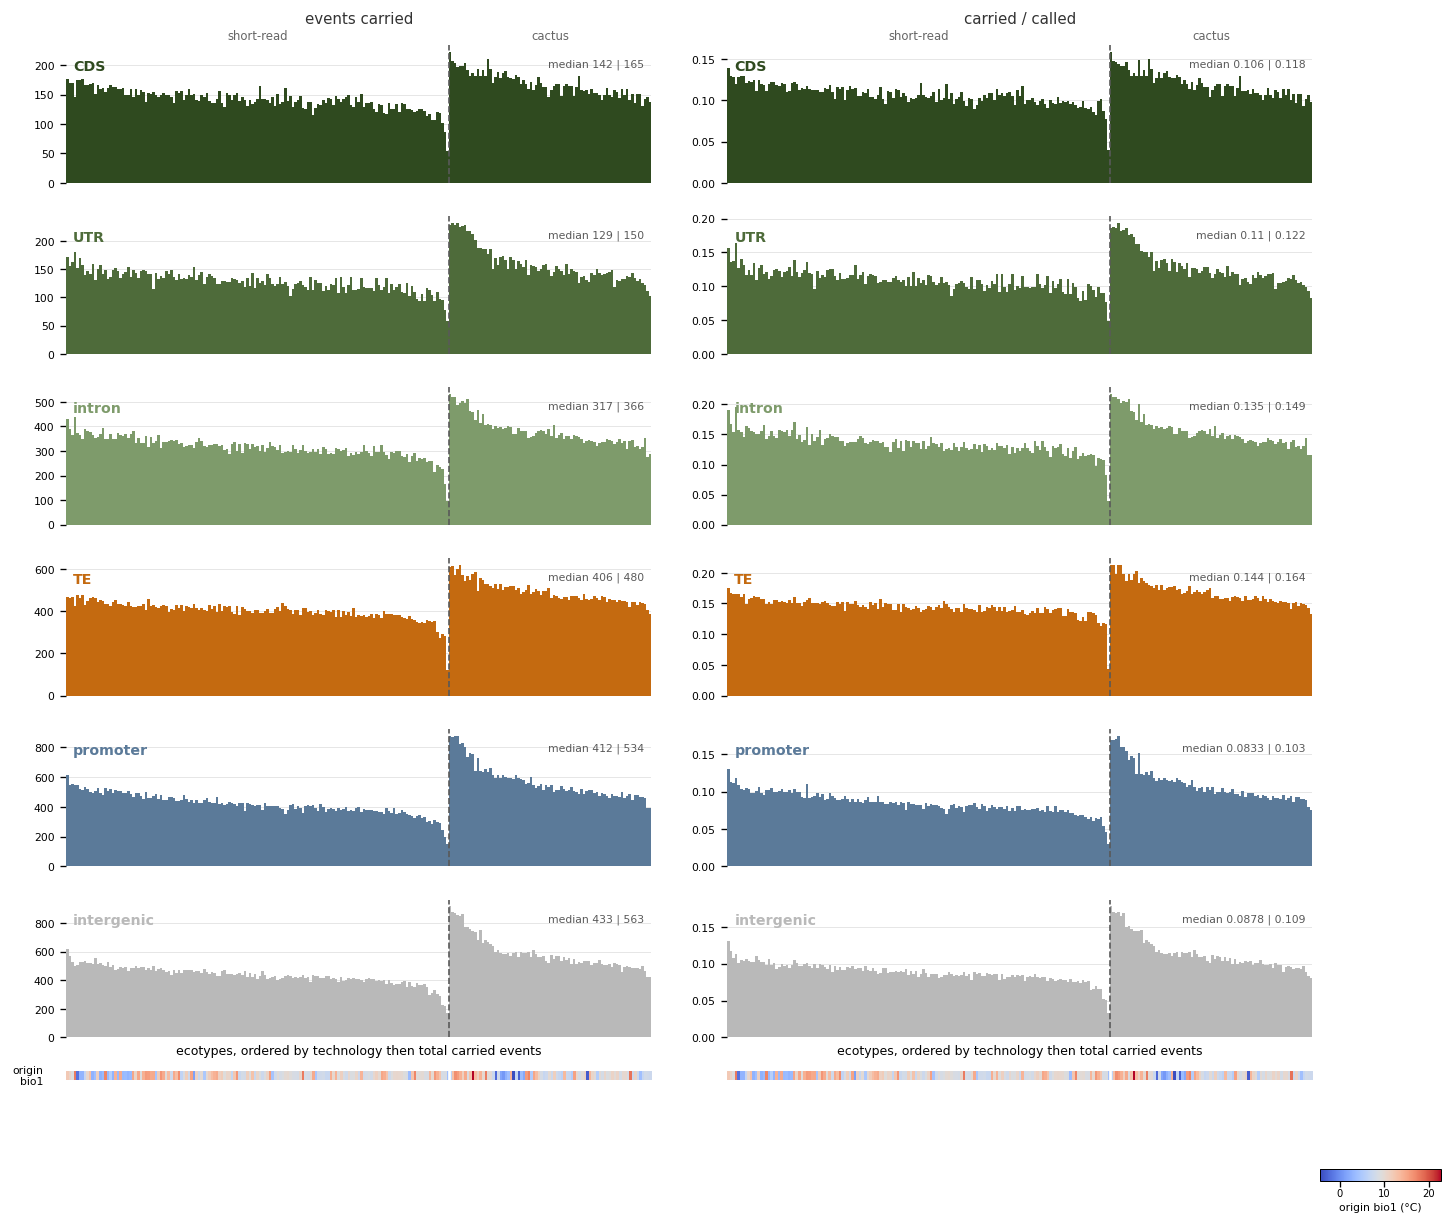

do the regions rise and fall together? correlation of each region's per-ecotype value
with the founder's TOTAL, across the 231 ecotypes:

    region  count vs total count  count vs total (others only)  rate vs summed rate  rate vs others' summed rate
       CDS                 0.921                         0.912                0.912                        0.887
       UTR                 0.944                         0.936                0.952                        0.928
    intron                 0.962                         0.948                0.964                        0.945
        TE                 0.958                         0.941                0.955                        0.936
  promoter                 0.988                         0.977                0.979                        0.968
intergenic                 0.988                         0.976                0.974                        0.962

(the 'others only' columns exclude the region itself from the total, s

In [6]:

fig=plt.figure(figsize=(13.4,11.2))
gsg2=fig.add_gridspec(len(CTX6)+1,2,height_ratios=[10]*len(CTX6)+[0.7],hspace=0.28,wspace=0.13)
for r_,c in enumerate(CTX6):
    for col,(M,unit) in enumerate(((car,"events carried"),(rate[CTX6],"carried / called"))):
        a=fig.add_subplot(gsg2[r_,col]); style(a,axis="y")
        a.bar(x,M[c].to_numpy()[ordr],width=1.0,color=CC[c],lw=0)
        a.set_xlim(-0.5,len(ordr)-0.5); a.set_xticks([])
        a.axvline(nsr-0.5,color="0.35",lw=1.0,ls="--")
        a.tick_params(labelsize=6.5)
        a.annotate(c,xy=(0.012,0.90),xycoords="axes fraction",fontsize=8.5,color=CC[c],
                   va="top",fontweight="bold")
        med_sr=M[c].to_numpy()[ordr][:nsr]; med_ca=M[c].to_numpy()[ordr][nsr:]
        a.annotate(f"median {np.median(med_sr):.3g} | {np.median(med_ca):.3g}",
                   xy=(0.988,0.90),xycoords="axes fraction",fontsize=6.5,color="0.35",
                   va="top",ha="right")
        if r_==0:
            a.annotate(unit,xy=(0.5,1.14),xycoords="axes fraction",ha="center",va="bottom",
                       fontsize=9,color="0.2",annotation_clip=False)
            for lab,x0,x1 in (("short-read",0,nsr),("cactus",nsr,len(ordr))):
                a.annotate(lab,xy=((x0+x1)/2/len(ordr),1.02),xycoords="axes fraction",ha="center",
                           va="bottom",fontsize=7,color="0.4",annotation_clip=False)
        if r_==len(CTX6)-1:
            a.set_xlabel("ecotypes, ordered by technology then total carried events",fontsize=7.5)
for col in (0,1):                                           # origin-climate strip under each column
    sx=fig.add_subplot(gsg2[len(CTX6),col])
    sx.imshow(BIO1[ordr][None,:],aspect="auto",cmap=CMc,norm=NORMc,interpolation="nearest")
    sx.set_yticks([]); sx.set_xticks([]); sx.set_xlim(-0.5,len(ordr)-0.5)
    sx.axvline(nsr-0.5,color="white",lw=1.6)
    for sp in sx.spines.values(): sp.set_visible(False)
    if col==0: sx.set_ylabel("origin\nbio1",fontsize=6.5,rotation=0,ha="right",va="center",labelpad=14)
cax=fig.add_axes([0.905,0.035,0.075,0.009])
cb=fig.colorbar(mpl.cm.ScalarMappable(norm=NORMc,cmap=CMc),cax=cax,orientation="horizontal")
cb.set_label("origin bio1 (°C)",fontsize=6.5,labelpad=2); cb.ax.tick_params(labelsize=6,pad=1)
save(fig,"founder_count_vs_rate_byregion",nb=True); plt.show()

print("do the regions rise and fall together? correlation of each region's per-ecotype value")
print("with the founder's TOTAL, across the 231 ecotypes:\n")
rows=[]
for c in CTX6:
    oth=[q for q in CTX6 if q!=c]
    rows.append({"region":c,
        "count vs total count":np.corrcoef(car[c],car.sum(1))[0,1],
        "count vs total (others only)":np.corrcoef(car[c],car[oth].sum(1))[0,1],
        "rate vs summed rate":np.corrcoef(rate[c],rate[CTX6].sum(1))[0,1],
        "rate vs others' summed rate":np.corrcoef(rate[c],rate[oth].sum(1))[0,1]})
print(pd.DataFrame(rows).to_string(index=False,float_format=lambda v:f"{v:.3f}"))
print("\n(the 'others only' columns exclude the region itself from the total, so the correlation")
print(" is not inflated by a region being part of its own denominator)")


## 1e · Does origin climate predict SV burden, region by region?

One column per genomic region. **Top row:** the raw number of SV events the ecotype carries in that region
against its **origin bio1** (mean annual temperature at the accession's home location). **Bottom row:** the
same corrected for call rate — carried / called within the region.

This is the direct test of the confound the burden model is exposed to. The model asks whether carrying
more SVs in a region changes fitness *as garden temperature rises*. If origin climate already predicts how
many SVs an ecotype carries, then a burden × garden-temperature term can pick up a founder-provenance
gradient rather than an effect of the variants.

Points are split by sequencing technology, and each panel reports the correlation overall and within each
technology separately, since technology is the other large source of between-ecotype variation.

Correcting for call rate rescales the y-axis by a per-region constant, so the correlation with bio1 is
essentially unchanged between the rows — the two rows differ in units, not in what they test. They are both
shown because the bottom row is the quantity the model is actually fitted on.

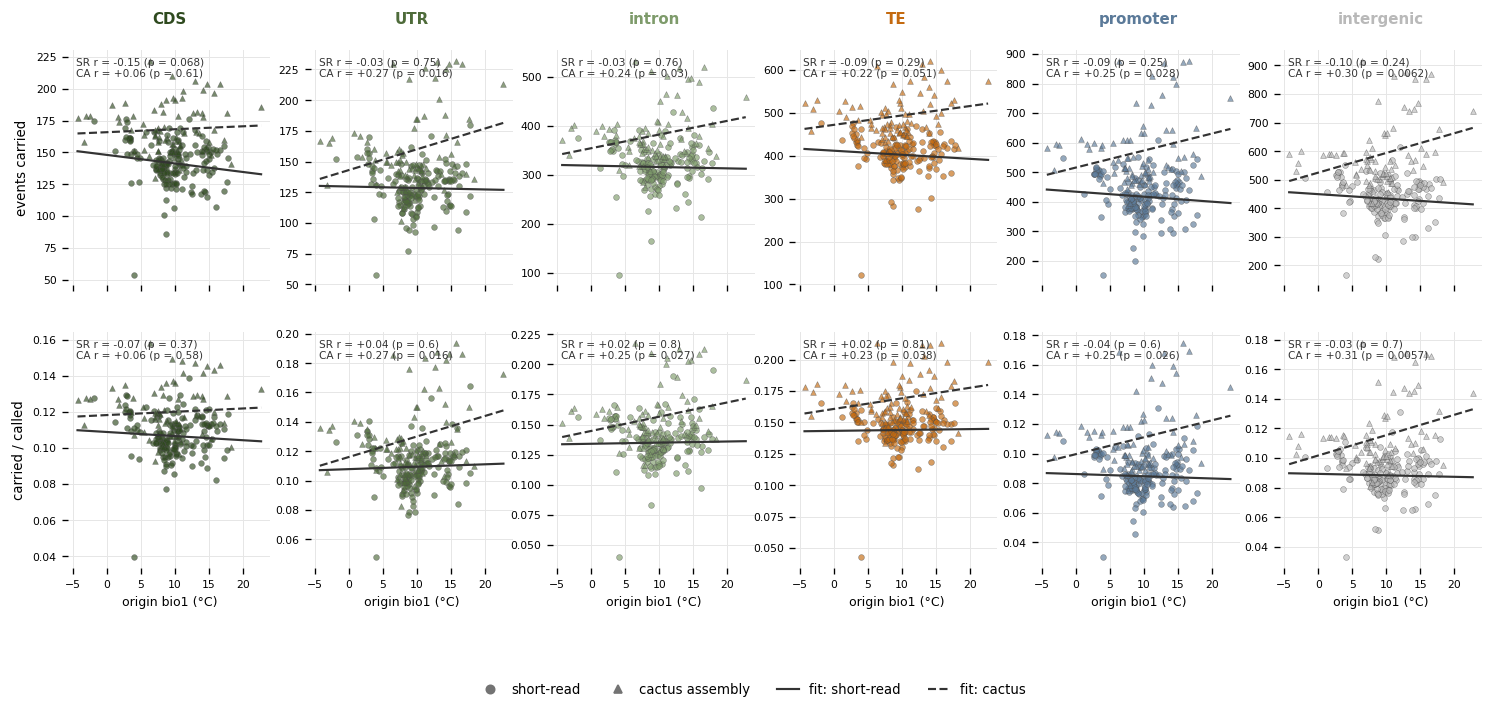

SV burden vs ORIGIN bio1, per region (231 ecotypes):

    region quantity      r     p  r short-read  r cactus
       CDS    count -0.093 0.159        -0.149     0.058
       CDS     rate -0.046 0.487        -0.074     0.063
       UTR    count  0.071 0.285        -0.026     0.268
       UTR     rate  0.112 0.090         0.043     0.269
    intron    count  0.043 0.513        -0.025     0.242
    intron     rate  0.080 0.226         0.021     0.247
        TE    count -0.019 0.771        -0.087     0.219
        TE     rate  0.047 0.476         0.020     0.233
  promoter    count  0.016 0.810        -0.095     0.246
  promoter     rate  0.045 0.493        -0.043     0.248
intergenic    count  0.038 0.566        -0.096     0.304
intergenic     rate  0.073 0.266        -0.032     0.307

origin bio1 by technology: short-read median 9.68 degC, cactus 9.43 degC, Mann-Whitney p = 0.235

Bonferroni over the 6 regions (rate row):
  CDS         r = -0.046   p = 0.487   Bonferroni x6 = 1
  UTR  

In [7]:

fig,axs=plt.subplots(2,len(CTX6),figsize=(15.2,5.6),sharex=True)
SUM=[]
for j,c in enumerate(CTX6):
    for i,(M,ylab) in enumerate(((car,"events carried"),(rate[CTX6],"carried / called"))):
        a=axs[i,j]; style(a,axis="both"); y=M[c].to_numpy()
        for t,mk in (("short-read","o"),("cactus","^")):
            m=TECH==t
            a.scatter(BIO1[m],y[m],s=12,marker=mk,color=CC[c],alpha=0.65,
                      linewidth=0.3,edgecolor="0.3",zorder=3)
        xx=np.linspace(BIO1.min(),BIO1.max(),40); lab=[]
        for t,ls in (("short-read","-"),("cactus","--")):    # one fit per technology, not a pooled line
            m=TECH==t
            a.plot(xx,np.polyval(np.polyfit(BIO1[m],y[m],1),xx),color="0.2",lw=1.3,ls=ls,zorder=4)
            rr_,pp_=sps0.pearsonr(BIO1[m],y[m])
            lab.append(f"{'SR' if t=='short-read' else 'CA'} r = {rr_:+.2f} (p = {pp_:.2g})")
        r,pv=sps0.pearsonr(BIO1,y)
        rsr=sps0.pearsonr(BIO1[TECH=="short-read"],y[TECH=="short-read"])[0]
        rca=sps0.pearsonr(BIO1[TECH=="cactus"],y[TECH=="cactus"])[0]
        a.annotate("\n".join(lab),xy=(0.04,0.97),xycoords="axes fraction",va="top",
                   fontsize=6.3,color="0.2")
        a.tick_params(labelsize=6.5)
        if i==0: a.annotate(c,xy=(0.5,1.10),xycoords="axes fraction",ha="center",va="bottom",
                            fontsize=9,color=CC[c],fontweight="bold",annotation_clip=False)
        if j==0: a.set_ylabel(ylab,fontsize=8)
        if i==1: a.set_xlabel("origin bio1 (°C)",fontsize=7.5)
        SUM.append({"region":c,"quantity":["count","rate"][i],"r":r,"p":pv,
                    "r short-read":rsr,"r cactus":rca})
h_=[axs[0,0].plot([],[],"o",color="0.45",ms=5,ls="none")[0],
    axs[0,0].plot([],[],"^",color="0.45",ms=5,ls="none")[0],
    axs[0,0].plot([],[],color="0.2",lw=1.3,ls="-")[0],
    axs[0,0].plot([],[],color="0.2",lw=1.3,ls="--")[0]]
fig.legend(h_,["short-read","cactus assembly","fit: short-read","fit: cactus"],loc="lower center",
           bbox_to_anchor=(0.5,-0.10),ncol=4,fontsize=8,handlelength=1.6)
save(fig,"founder_region_vs_bio1",nb=True); plt.show()

S=pd.DataFrame(SUM)
print("SV burden vs ORIGIN bio1, per region (231 ecotypes):\n")
print(S.to_string(index=False,float_format=lambda v:f"{v:.3f}"))
# is technology itself associated with origin climate? if not, it cannot manufacture a bio1 gradient
u=sps0.mannwhitneyu(BIO1[TECH=="short-read"],BIO1[TECH=="cactus"])
print(f"\norigin bio1 by technology: short-read median {np.median(BIO1[TECH=='short-read']):.2f} degC, "
      f"cactus {np.median(BIO1[TECH=='cactus']):.2f} degC, Mann-Whitney p = {u.pvalue:.3g}")
print("\nBonferroni over the 6 regions (rate row):")
for r_ in S[S.quantity=="rate"].itertuples():
    print(f"  {r_.region:<11} r = {r_.r:+.3f}   p = {r_.p:.3g}   Bonferroni x6 = {min(r_.p*6,1):.3g}"
          f"{'   **' if r_.p*6<0.05 else ''}")

def ols(y,X):
    X=np.column_stack([np.ones(len(y))]+[np.asarray(cc,float) for cc in X])
    b,_,_,_=np.linalg.lstsq(X,y,rcond=None); r_=y-X@b; n,k=X.shape
    s2=(r_@r_)/(n-k); V=s2*np.linalg.pinv(X.T@X); se=np.sqrt(np.diag(V))
    return b,se,2*sps0.t.sf(np.abs(b/se),n-k)
print("\n\nDO THE TWO FITS GENUINELY DIFFER?  burden ~ bio1 + is_cactus + bio1 x is_cactus\n")
IC=(TECH=="cactus").astype(float); out=[]
for c in CTX6:
    for M,q in ((car,"count"),(rate[CTX6],"rate")):
        yv=M[c].to_numpy().astype(float); b,se,pv=ols(yv,[BIO1,IC,BIO1*IC])
        out.append({"region":c,"quantity":q,"slope short-read":b[1],"slope difference":b[3],
                    "interaction p":pv[3],"Bonferroni x12":min(pv[3]*12,1)})
O=pd.DataFrame(out); print(O.to_string(index=False,float_format=lambda v:f"{v:.4g}"))
sg=O[O["Bonferroni x12"]<0.05]
print("\nregions where the two slopes genuinely differ (Bonferroni < 0.05):",
      ", ".join(f"{r.region} ({r.quantity})" for r in sg.itertuples()) if len(sg) else "NONE")


## 2 · Do ecotypes with more TE events have more promoter events?

The direct question. Across the 231 founders, correlate the **burden rates** (carried / called per context)
— the quantity the model uses — for every pair of modelled contexts.

Two versions, because the raw correlation is not the interesting one:

- **raw** — Pearson *r* between the two context rates.
- **partial, controlling total SV rate** — a founder that simply carries more SVs carries more of
  *everything*, which induces positive correlation between all contexts regardless of any shared biology.
  Residualising both contexts on the founder's total carried/called rate removes that, and asks whether TE
  and promoter covary **beyond** overall SV load.

`sv_TE` and `sv_promoter` competing in the model requires correlation in the **raw** predictors, since that
is what the design matrix sees. The partial version says whether the overlap is just shared SV load or
something more specific.

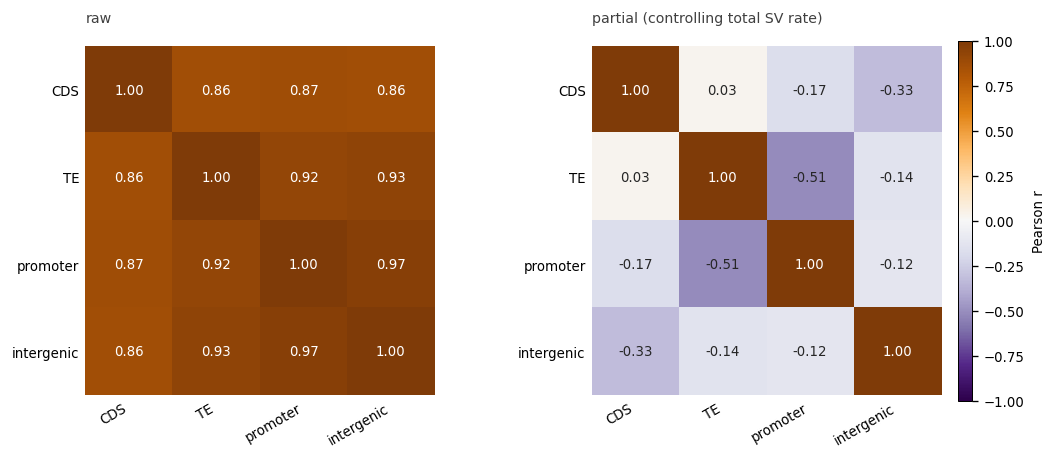

raw correlations between context burden rates (events, 231 founders):
              CDS     TE  promoter  intergenic
CDS         1.000  0.861     0.874       0.860
TE          0.861  1.000     0.917       0.933
promoter    0.874  0.917     1.000       0.968
intergenic  0.860  0.933     0.968       1.000

partial, controlling the founder's total SV event rate:
              CDS     TE  promoter  intergenic
CDS         1.000  0.029    -0.169      -0.327
TE          0.029  1.000    -0.509      -0.135
promoter   -0.169 -0.509     1.000      -0.121
intergenic -0.327 -0.135    -0.121       1.000

TE vs promoter:  raw r = 0.917   partial r = -0.509


In [8]:

def resid(y,X):
    X=np.column_stack([np.ones(len(y))]+[np.asarray(c,float) for c in X])
    return y-X@np.linalg.lstsq(X,y,rcond=None)[0]
tot=(car.sum(axis=1)/cal.sum(axis=1)).to_numpy()            # overall SV event rate per founder
Rraw=rate[MODCTX].corr()
Rpar=pd.DataFrame(np.eye(len(MODCTX)),index=MODCTX,columns=MODCTX)
for i,ci in enumerate(MODCTX):
    for cj in MODCTX[i+1:]:
        r=np.corrcoef(resid(rate[ci].to_numpy(),[tot]),resid(rate[cj].to_numpy(),[tot]))[0,1]
        Rpar.loc[ci,cj]=Rpar.loc[cj,ci]=r
fig,ax=plt.subplots(1,2,figsize=(9.6,3.9),gridspec_kw=dict(wspace=0.45))
for a,M,lab in zip(ax,(Rraw,Rpar),("raw","partial (controlling total SV rate)")):
    im=a.imshow(M.to_numpy(),cmap="PuOr_r",vmin=-1,vmax=1)
    a.set_xticks(range(len(MODCTX))); a.set_xticklabels(MODCTX,fontsize=8,rotation=30,ha="right")
    a.set_yticks(range(len(MODCTX))); a.set_yticklabels(MODCTX,fontsize=8)
    for i in range(len(MODCTX)):
        for j in range(len(MODCTX)):
            v=M.to_numpy()[i,j]
            a.annotate(f"{v:.2f}",xy=(j,i),ha="center",va="center",fontsize=8,
                       color="white" if abs(v)>0.55 else "0.15")
    a.annotate(lab,xy=(0,1.06),xycoords="axes fraction",fontsize=8.5,color="0.25",va="bottom")
    for sp in a.spines.values(): sp.set_visible(False)
    a.tick_params(length=0)
cb=fig.colorbar(im,ax=ax,pad=0.02,fraction=0.022,aspect=26); cb.set_label("Pearson r",fontsize=8)
save(fig,"founder_context_correlations",nb=True); plt.show()
print("raw correlations between context burden rates (events, 231 founders):")
print(Rraw.round(3).to_string())
print("\npartial, controlling the founder's total SV event rate:")
print(Rpar.round(3).to_string())
print(f"\nTE vs promoter:  raw r = {Rraw.loc['TE','promoter']:.3f}   "
      f"partial r = {Rpar.loc['TE','promoter']:.3f}")


### The TE–promoter pair on its own

The pair that matters for the model, drawn out: each point is one ecotype, coloured by origin climate and
shaped by sequencing technology. Because technology and origin climate are both candidate drivers of a
founder's SV content, the panel reports the correlation overall and within each technology separately — a
correlation that exists only *between* the two technology blocks would be a batch effect, not biology.

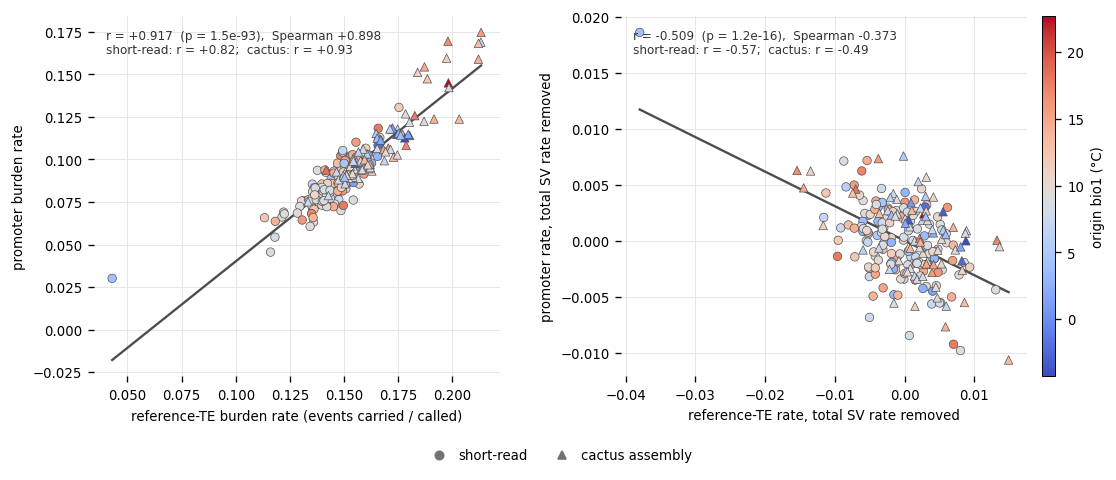

In [9]:

from scipy import stats as sps
fig,ax=plt.subplots(1,2,figsize=(10.4,3.9),gridspec_kw=dict(wspace=0.30))
for a,(xv,yv,xl,yl) in zip(ax,[(rate["TE"].to_numpy(),rate["promoter"].to_numpy(),
                                "reference-TE burden rate (events carried / called)",
                                "promoter burden rate"),
                               (resid(rate["TE"].to_numpy(),[tot]),resid(rate["promoter"].to_numpy(),[tot]),
                                "reference-TE rate, total SV rate removed","promoter rate, total SV rate removed")]):
    style(a,axis="both")
    for t,mk in (("short-read","o"),("cactus","^")):
        m=TECH==t
        a.scatter(xv[m],yv[m],s=26,marker=mk,c=BIO1[m],cmap=CMc,norm=NORMc,
                  linewidth=0.4,edgecolor="0.3",zorder=3)
    b=np.polyfit(xv,yv,1); xx=np.linspace(xv.min(),xv.max(),50)
    a.plot(xx,np.polyval(b,xx),color="0.3",lw=1.4,zorder=2)
    r,p=sps.pearsonr(xv,yv); rs,_=sps.spearmanr(xv,yv)
    sub=[f"{t}: r = {sps.pearsonr(xv[TECH==t],yv[TECH==t])[0]:+.2f}" for t in ("short-read","cactus")]
    a.annotate(f"r = {r:+.3f}  (p = {p:.2g}),  Spearman {rs:+.3f}\n"+";  ".join(sub),
               xy=(0.03,0.96),xycoords="axes fraction",va="top",fontsize=7.2,color="0.2")
    a.set_xlabel(xl,fontsize=8); a.set_ylabel(yl,fontsize=8)
h_=[ax[0].plot([],[],"o",color="0.45",ms=5)[0],ax[0].plot([],[],"^",color="0.45",ms=5)[0]]
fig.legend(h_,["short-read","cactus assembly"],loc="lower center",bbox_to_anchor=(0.5,-0.10),
           ncol=2,fontsize=8,handlelength=1.2)
cb=fig.colorbar(mpl.cm.ScalarMappable(norm=NORMc,cmap=CMc),ax=ax,pad=0.015,fraction=0.02,aspect=26)
cb.set_label("origin bio1 (°C)",fontsize=8)
save(fig,"founder_te_promoter_scatter",nb=True); plt.show()


## 3 · Is variance sharing actually the mechanism? — no

The correlation above is the cause; this section asks what consequence it has in the model's own terms.
The motivating observation was that dropping `sv_TE` moves the promoter × temperature interaction by ~170×.
The natural explanation is **variance inflation**: two correlated predictors compete, each widening the
other's standard error, so removing one should sharpen the other. This section tests that explanation
directly — and it fails.

**Variance inflation factor** for each burden term, computed on the standardised founder-level rates the
model is fitted on, with and without `sv_TE` in the predictor set. VIF is 1/(1 − R²) from regressing that
predictor on the others: VIF = 2 means the term's standard error is √2 ≈ 1.41× wider than it would be if
the predictor were orthogonal to the rest.

Three things to read off the cell below, in order:

1. **`sv_promoter`'s VIF barely changes when `sv_TE` is dropped** (22.25 → 22.17). If collinearity with
   `sv_TE` were the mechanism, this is the number that would have to move, and it does not.
2. **The leave-one-out table says why.** `sv_TE` is the *least* important of `sv_promoter`'s collinearity
   partners — `snp_CDS` and `sv_intergenic` matter far more. `sv_promoter` is ~95 % predictable from the
   other predictors either way.
3. **The fitted models confirm it.** Between the two published fits the promoter × temperature *standard
   error* moves ~11 % while the *estimate* moves ~50 %. A precision effect would show the opposite.

So the ~170× is **omitted-variable signal reallocation, not variance inflation**: `sv_TE:bio1c` is itself
non-zero and same-signed, and when it is removed its signal migrates onto the correlated promoter term.
That is a statement about bias, not about standard errors, and it is the reason this section's conclusion
changed. (Of the 170×, a factor 1.5 is merely the Bonferroni count dropping from ×3 to ×2; the raw LRT
move is ~117×.)

variance inflation among the founder-level burden predictors (231 founders, events):
         term  VIF with sv_TE  VIF without sv_TE  SE inflation with
      snp_CDS           18.93              16.42               4.35
       sv_CDS            5.10               4.77               2.26
        sv_TE           10.63                NaN               3.26
  sv_promoter           24.31              23.82               4.93
sv_intergenic           21.45              19.72               4.63
       cactus            3.09               2.56               1.76


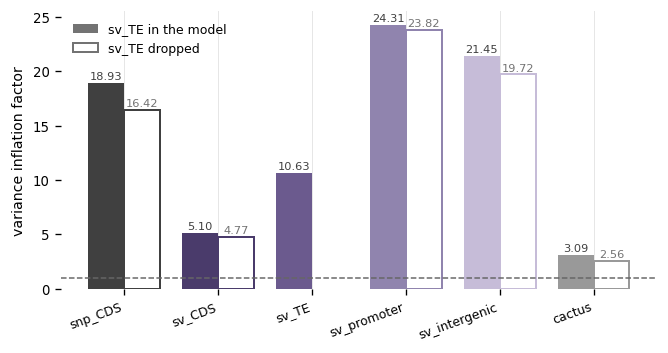


sv_promoter's VIF when each OTHER predictor is dropped in turn:
  full predictor set             24.31
  drop snp_CDS                   18.02   (-25.9%)
  drop sv_CDS                    23.63   ( -2.8%)
  drop sv_TE                     23.82   ( -2.0%)
  drop sv_intergenic             17.34   (-28.7%)
  drop cactus                    21.76   (-10.5%)

  R^2 of sv_promoter on the other predictors: 0.9589 with sv_TE, 0.9580 without.
  These are not four independent predictors; they are close to one axis of founder SV content.

the published fits, sv_promoter:bio1c:
  estimate  +0.03331 -> +0.04988   (+50%)
  SE         0.01385 ->  0.01228   (-11%)
  z          2.405  ->  4.062

  share of the log-z gain from the ESTIMATE moving (bias)      : 77%
  share from the SE shrinking (the variance-inflation story)   : 23%

  what sv_TE was carrying: sv_TE:bio1c = +0.02324 (p = 0.018) -- same sign as the promoter interaction, so dropping it
  pushes the promoter estimate up. That is reallocation 

In [10]:

from matplotlib.patches import Patch
L=pd.read_csv(f"{R1}/onestage_all/long.csv").drop_duplicates("founder")
L["founder"]=L.founder.astype(str)
Z=pd.DataFrame({f"sv_{c}": (rate[c]-rate[c].mean())/rate[c].std(ddof=1) for c in MODCTX})
Z.index=rate.index
Z=Z.join(L.set_index("founder")[["snp_CDS","cactus"]])
def vif(cols):
    out={}
    for t in cols:
        y=Z[t].to_numpy(float); X=Z[[c for c in cols if c!=t]].to_numpy(float)
        X=np.column_stack([np.ones(len(y)),X])
        r2=1-((y-X@np.linalg.lstsq(X,y,rcond=None)[0])**2).sum()/((y-y.mean())**2).sum()
        out[t]=1/(1-r2) if r2<1 else np.inf
    return out
WITH=["snp_CDS","sv_CDS","sv_TE","sv_promoter","sv_intergenic","cactus"]
WOUT=[c for c in WITH if c!="sv_TE"]
vw,vo=vif(WITH),vif(WOUT)
rows=[{"term":t,"VIF with sv_TE":round(vw[t],2),
       "VIF without sv_TE":round(vo[t],2) if t in vo else None,
       "SE inflation with":round(np.sqrt(vw[t]),2)} for t in WITH]
print("variance inflation among the founder-level burden predictors (231 founders, events):")
print(pd.DataFrame(rows).to_string(index=False))
fig,a=plt.subplots(figsize=(6.4,3.0)); style(a)
PALV={"snp_CDS":"0.25","sv_CDS":"#4A3B6B","sv_TE":"#6B5A8E","sv_promoter":"#9084AE",
      "sv_intergenic":"#C6BCD8","cactus":"0.6"}
xs=np.arange(len(WITH)); w=0.38
a.bar(xs-w/2,[vw[t] for t in WITH],width=w,color=[PALV[t] for t in WITH],lw=0)
a.bar(xs+w/2,[vo.get(t,np.nan) for t in WITH],width=w,color="white",
      edgecolor=[PALV[t] for t in WITH],lw=1.2)
for i,t in enumerate(WITH):
    a.annotate(f"{vw[t]:.2f}",xy=(i-w/2,vw[t]),xytext=(0,2),textcoords="offset points",
               ha="center",fontsize=6.8,color="0.25")
    if t in vo: a.annotate(f"{vo[t]:.2f}",xy=(i+w/2,vo[t]),xytext=(0,2),textcoords="offset points",
                           ha="center",fontsize=6.8,color="0.45")
a.axhline(1,color="0.4",lw=0.9,ls="--")
a.set_xticks(xs); a.set_xticklabels(WITH,fontsize=7.5,rotation=20,ha="right")
a.set_ylabel("variance inflation factor",fontsize=8.5)
h_=[Patch(facecolor="0.45"),Patch(facecolor="white",edgecolor="0.45",lw=1.2)]
a.legend(h_,["sv_TE in the model","sv_TE dropped"],fontsize=7.5,loc="upper left")
save(fig,"founder_burden_vif",nb=True); plt.show()

# 2. WHICH predictor is sv_promoter actually collinear with? Drop each of the others in turn and watch
#    sv_promoter's VIF. The one whose removal moves it is the real partner -- sv_TE barely registers.
print("\nsv_promoter's VIF when each OTHER predictor is dropped in turn:")
print(f"  {'full predictor set':<28} {vw['sv_promoter']:7.2f}")
for d in WITH:
    if d=="sv_promoter": continue
    v_=vif([c for c in WITH if c!=d])["sv_promoter"]
    print(f"  drop {d:<23} {v_:7.2f}   ({100*(v_/vw['sv_promoter']-1):+5.1f}%)")
print(f"\n  R^2 of sv_promoter on the other predictors: {1-1/vw['sv_promoter']:.4f} with sv_TE, "
      f"{1-1/vo['sv_promoter']:.4f} without.")
print("  These are not four independent predictors; they are close to one axis of founder SV content.")

# 3. The fitted models themselves: does dropping sv_TE sharpen the promoter interaction (a precision
#    effect, which is what collinearity predicts) or move it (a bias effect)? Read, not refitted.
PD=f"{R1}/final_models_pooled_all"; PN=f"{R1}/final_models_pooled_all_noTE"
cT=pd.read_csv(f"{PD}/coef_M2p_reml.csv").set_index("term")          # sv_TE in
cN=pd.read_csv(f"{PN}/coef_M2p_reml.csv").set_index("term")          # sv_TE dropped
n="sv_promoter:bio1c"
eT,sT=cT.loc[n,"estimate"],cT.loc[n,"se"]; eN,sN=cN.loc[n,"estimate"],cN.loc[n,"se"]
print(f"\nthe published fits, {n}:")
print(f"  estimate  {eT:+.5f} -> {eN:+.5f}   ({100*(eN/eT-1):+.0f}%)")
print(f"  SE         {sT:.5f} ->  {sN:.5f}   ({100*(sN/sT-1):+.0f}%)")
print(f"  z          {eT/sT:.3f}  ->  {eN/sN:.3f}")
_le,_ls=np.log(eN/eT),np.log(sT/sN)
print(f"\n  share of the log-z gain from the ESTIMATE moving (bias)      : {100*_le/(_le+_ls):.0f}%")
print(f"  share from the SE shrinking (the variance-inflation story)   : {100*_ls/(_le+_ls):.0f}%")
print(f"\n  what sv_TE was carrying: sv_TE:bio1c = {cT.loc['sv_TE:bio1c','estimate']:+.5f} "
      f"(p = {cT.loc['sv_TE:bio1c','p']:.3g}) -- same sign as the promoter interaction, so dropping it")
print("  pushes the promoter estimate up. That is reallocation of signal, not recovery of precision.")


## 4 · Reading it

The numbers are printed by the cells above; what they add up to is this.

**TE and promoter rates are strongly correlated raw (r ≈ 0.92) — but so is everything else.** After
residualising on the founder's total SV rate the TE–promoter partial correlation goes *negative*
(≈ −0.48), and §1d shows every region correlating 0.89–0.97 with the *others'* total. The raw correlation
is overwhelmingly "some founders simply carry more SVs", and it is not specific to TEs and promoters.

**Variance sharing is therefore not why the model moves.** §3 tests the natural explanation and it fails:
`sv_promoter`'s VIF is unchanged by dropping `sv_TE`, `sv_TE` is its weakest collinearity partner, and in
the fitted models the promoter × temperature *estimate* moves ~50 % while its *standard error* moves ~11 %.
The ~170× is a **bias** effect — `sv_TE:bio1c` is genuinely non-zero and same-signed, so removing it hands
its signal to the correlated promoter term.

**The real modelling problem here is bigger than TE.** `sv_promoter` is ~95 % predictable from the other
burden predictors whether or not `sv_TE` is present. These four terms are close to a single axis of founder
SV content, so *any* one of them can stand in for the others, and which context a signal gets attributed to
is weakly identified. That is a caveat on every per-context burden coefficient in this section, not just on
the TE comparison.

**Pooling is doing some of the work.** In the split model the TE interaction is carried almost entirely by
*insertions* (`ins_TE:bio1c` p ≈ 5 × 10⁻⁴ vs `del_TE:bio1c` p ≈ 0.71), and the headline promoter
*deletion* interaction barely moves when the TE terms are dropped (−9 %). The dramatic version of this
result is specific to the pooled parameterisation and should not be read across to the reported split
model.

The technology split (§1e, §2) is reassuring on a separate question: the correlation holds *within* each
sequencing panel, so it is not a batch effect between the short-read and cactus assemblies — and origin
climate does not predict per-region SV burden after Bonferroni correction. Note that the latter is a
statement about the *marginal* association; `sv_burden_origin_climate_control.ipynb` shows that origin
climate nonetheless matters a great deal once it is in the fitted model as an interaction with garden
climate.

⚠ **Composition is compositional.** The stacked bars sum to 100 % by construction, so the context shares
are negatively correlated with one another whether or not anything biological links them. That is why the
correlations in §2 use **rates**, not composition shares, and why the bar figure is presented as a picture
of each ecotype rather than as evidence of covariation.

## As run

- **Counts.** `results/sv_adaptive/founder_burden_event.csv` — truvari-collapsed SV **events** per founder
  per context, insertions and deletions summed, origin class `all` (no `shared` filter), frequency class
  `all`. Carried = `ins_all_<ctx>_all + del_all_<ctx>_all`; called =
  `called_ins_all_<ctx>_all + called_del_all_<ctx>_all`. The allele-level table
  (`founder_burden_allele.csv`) is not read anywhere in this notebook.
- **Founder metadata.** Taken from `founder_burden_event.csv` itself — `bio1` (origin climate at the
  accession's home location), `group` (cold / temperate / warm tertiles, 77 each) and `is_cactus`
  (assembly route: cactus vs short-read). The load cell asserts these agree exactly with
  `sv_origin_partition_founders.csv` on all 231 founders, so reading one table cannot let the metadata
  drift out of step with the burden rows it labels.
- **Standardised predictors for the VIF.** Rates z-scored across the 231 founders exactly as
  `_sv_burden_pooled_models.R` does, with `snp_CDS` and `cactus` taken from `onestage_all/long.csv` so the
  predictor set matches the fitted model's.
- **Context rule and palette.** First match CDS > UTR > intron > reference TE > promoter ≤ 2 kb >
  intergenic; colours lifted from `_build_context_cascade_nb.py` so the per-ecotype bars read directly
  against the pooled cascade bar. Origin climate uses coolwarm, the temperature scale used throughout.
- **Nothing is fitted here.** Every model coefficient referenced in the text comes from
  `sv_burden_pooled_nofilter.ipynb` (TE in) and `sv_burden_pooled_nofilter_noTE.ipynb` (TE dropped).